# Jaipur Junction-Informed Railway Platform Allocation — Diagnostic Benchmark V6

## Purpose
V6 is a **solver-diagnostics and tuning study**, not another increase in problem size. It keeps the V5 railway objective, constraints and deterministic synthetic data generator unchanged, and investigates why OpenJij SA/SQA struggled against the Greedy baseline.

### V6 questions
1. Does the one-hot QUBO encoding create a large energy barrier between valid platform assignments?
2. Does seeding Exact Search with a valid Greedy assignment help it prove optimality faster?
3. Do alternative SA inverse-temperature ranges or SQA schedules improve solution quality and feasibility?
4. Can a transparent feasibility-repair decoder recover useful assignments from invalid SA/SQA samples?

### Fixed railway model (unchanged from V5)
- Six abstract platform resources; four long-train-capable platforms in the primary scenario.
- Trains with 24 or more coaches may use only the long-train-capable platforms.
- Two trains cannot occupy the same platform when their actual occupation intervals, including five minutes of clearance, overlap.
- Objective: minimise the number of trains moved away from their nominal platform.
- Nominal schedules are generated conflict-free; independent arrival delays shift arrival and departure together.

### Dataset design
V6 re-generates the same deterministic V5 dataset IDs for the larger cases: **20, 24 and 28 trains × 15 and 30 minute delay levels × seeds 11, 22 and 33 = 18 datasets**. This allows direct comparison with V5. The train-level schedules, delays and nominal platform assignments remain synthetic.

### Interpretation limits
This is a **Jaipur Junction-informed synthetic benchmark**, not actual Jaipur train-level operational data. OpenJij SQA is a classical simulation, not a quantum-hardware run. V6 must not be used to claim quantum advantage.

## 0. Setup
Run this in the same Python environment where OpenJij 0.12.2 worked for V5. If packages are already installed, this cell may be skipped.

In [1]:
%pip install -q openjij numpy pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and machine information

In [2]:
import sys, platform, time, itertools, math, json, os, random, importlib.metadata
from pathlib import Path
from typing import Dict, List, Tuple, Optional
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import openjij as oj
except ImportError as exc:
    raise ImportError("OpenJij is required. Install it in this notebook kernel and restart the kernel.") from exc

try:
    import psutil
    RAM_GB = round(psutil.virtual_memory().total / 1024**3, 2)
except Exception:
    RAM_GB = None
try:
    OPENJIJ_VERSION = importlib.metadata.version("openjij")
except Exception:
    OPENJIJ_VERSION = getattr(oj, "__version__", "version not exposed")

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("CPU:", platform.processor() or "not exposed")
print("RAM GB:", RAM_GB)
print("OpenJij:", OPENJIJ_VERSION)
try:
    import torch
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
except Exception:
    print("PyTorch/CUDA not installed; OpenJij calls here are CPU sampler calls.")

Python: 3.12.12
Platform: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 143 Stepping 8, GenuineIntel
RAM GB: 127.65
OpenJij: 0.12.2
PyTorch/CUDA not installed; OpenJij calls here are CPU sampler calls.


## 2. V6 experiment controls
The main set is deliberately limited to the large V5 cases (18 datasets). Exact Search is given a Greedy feasible incumbent and a longer per-dataset time limit. Tuning is restricted to three representative datasets to keep the sweep manageable.

In [3]:
# Fixed problem settings — do not alter for a V5-to-V6 comparison
N_PLATFORMS = 6
PEAK_WINDOW_START = 12 * 60
PEAK_WINDOW_END = 18 * 60
BASE_CLEARANCE_MIN = 5
LONG_TRAIN_COACH_THRESHOLD = 24
LONG_PLATFORM_COUNT_MAIN = 4

# Same deterministic V5 generator parameters, subset to the larger workloads.
TRAIN_COUNTS_V6 = [20, 24, 28]
DELAY_LEVELS_V6 = [15, 30]
DATASET_SEEDS = [11, 22, 33]

# Main default-settings comparison
BASELINE_REPEATS = 2
NUM_READS = 100
NUM_SWEEPS = 1000
GREEDY_RESTARTS = 30
EXACT_TIME_LIMIT_BY_N = {20: 10.0, 24: 20.0, 28: 30.0}

# Energy landscape is evaluated on representative large datasets only.
ENERGY_DIAG_IDS = [
    "N20_D30_S11_L4", "N20_D30_S33_L4",
    "N24_D30_S11_L4", "N24_D30_S33_L4",
    "N28_D30_S11_L4", "N28_D30_S33_L4",
]

# Solver tuning: only these fixed instances are used for tuning comparisons.
CALIBRATION_IDS = ["N20_D30_S33_L4", "N24_D30_S33_L4", "N28_D30_S33_L4"]
CALIBRATION_REPEATS = 2
CALIBRATION_READS = 100
CALIBRATION_SWEEPS = 1000

RUN_MAIN_BENCHMARK = True
RUN_ENERGY_DIAGNOSTICS = True
RUN_CALIBRATION_SWEEP = True

EXPECTED_DATASETS = len(TRAIN_COUNTS_V6) * len(DELAY_LEVELS_V6) * len(DATASET_SEEDS)
print("Main unique datasets:", EXPECTED_DATASETS)
print("Default SA/SQA sampler calls:", EXPECTED_DATASETS * 2 * BASELINE_REPEATS)
print("Exact time limits:", EXACT_TIME_LIMIT_BY_N)
print("The primary QUBO penalty stays lambda = N + 1, as in V5.")

Main unique datasets: 18
Default SA/SQA sampler calls: 72
Exact time limits: {20: 10.0, 24: 20.0, 28: 30.0}
The primary QUBO penalty stays lambda = N + 1, as in V5.


## 3. V5 synthetic timetable generator and independent validator
This cell is copied from V5 without changing the generation rules. The resulting dataset IDs are the same as V5 for matching train count, delay and seed.

In [4]:
def scheduled_same_platform_conflicts(df: pd.DataFrame, clearance_min: int):
    conflicts = []
    for i in range(len(df)):
        si = int(df.iloc[i].scheduled_arrival_min)
        ei = int(df.iloc[i].scheduled_departure_min) + clearance_min
        for j in range(i + 1, len(df)):
            if int(df.iloc[i].nominal_platform) != int(df.iloc[j].nominal_platform):
                continue
            sj = int(df.iloc[j].scheduled_arrival_min)
            ej = int(df.iloc[j].scheduled_departure_min) + clearance_min
            if max(si, sj) < min(ei, ej): conflicts.append((i, j))
    return conflicts


def generate_jaipur_profile_instance(n_trains: int, seed: int, delay_max_min: int,
                                     long_platform_count: int = LONG_PLATFORM_COUNT_MAIN,
                                     long_train_count: Optional[int] = None,
                                     clearance_min: int = BASE_CLEARANCE_MIN,
                                     n_platforms: int = N_PLATFORMS) -> pd.DataFrame:
    if n_trains < 1: raise ValueError("n_trains must be positive")
    if not 1 <= long_platform_count <= n_platforms: raise ValueError("Invalid long_platform_count")
    if delay_max_min < 0 or clearance_min < 0: raise ValueError("Delay and clearance must be non-negative")
    rng = np.random.default_rng(seed)
    if long_train_count is None:
        long_train_count = min(n_trains, max(1, round(n_trains * 18 / 97)))
    if not 0 <= long_train_count <= n_trains: raise ValueError("Invalid long_train_count")

    long_flags = np.array([True] * long_train_count + [False] * (n_trains - long_train_count))
    rng.shuffle(long_flags)
    long_eligible = set(range(long_platform_count))
    eligible = [sorted(long_eligible) if flag else list(range(n_platforms)) for flag in long_flags]

    # Load-balanced nominal assignment respecting coach-length eligibility.
    platform_load = np.zeros(n_platforms, dtype=int)
    nominal_platforms = []
    for i in range(n_trains):
        candidates = eligible[i]
        min_load = min(platform_load[p] for p in candidates)
        choices = [p for p in candidates if platform_load[p] == min_load]
        chosen = int(rng.choice(choices))
        nominal_platforms.append(chosen)
        platform_load[chosen] += 1

    arr_nom = np.zeros(n_trains, dtype=int)
    dep_nom = np.zeros(n_trains, dtype=int)
    for p in range(n_platforms):
        idxs = [i for i, pp in enumerate(nominal_platforms) if pp == p]
        if not idxs: continue
        rng.shuffle(idxs)
        count = len(idxs)
        n_small_gaps = (count - 1 + 1) // 2
        n_large_gaps = (count - 1) // 2
        max_span = count * (22 + clearance_min) + n_small_gaps * 5 + n_large_gaps * 60
        latest_start_offset = max(0, (PEAK_WINDOW_END - PEAK_WINDOW_START) - max_span)
        cursor = PEAK_WINDOW_START + int(rng.integers(0, latest_start_offset + 1))
        for position, i in enumerate(idxs):
            if position > 0:
                previous_position = position - 1
                gap = int(rng.integers(1, 6)) if previous_position % 2 == 0 else int(rng.integers(30, 61))
                cursor += gap
            dwell = int(rng.integers(12, 23))
            arr_nom[i] = cursor
            dep_nom[i] = cursor + dwell
            cursor = dep_nom[i] + clearance_min

    delays = rng.integers(0, delay_max_min + 1, size=n_trains)
    arr_actual = arr_nom + delays
    dep_actual = dep_nom + delays
    coach_draws = rng.choice([12, 16, 18, 22, 24, 26], size=n_trains, p=[.08, .15, .22, .20, .22, .13])
    coaches = np.where(long_flags, np.maximum(coach_draws, LONG_TRAIN_COACH_THRESHOLD), np.minimum(coach_draws, 22))

    rows = []
    for i in range(n_trains):
        rows.append({
            "train_index": i, "train_id": f"J{i+1:02d}", "coaches": int(coaches[i]),
            "is_long": bool(long_flags[i]), "nominal_platform": int(nominal_platforms[i]),
            "eligible_platforms": list(eligible[i]),
            "scheduled_arrival_min": int(arr_nom[i]), "scheduled_departure_min": int(dep_nom[i]),
            "delay_min": int(delays[i]), "actual_arrival_min": int(arr_actual[i]),
            "actual_departure_min": int(dep_actual[i]),
        })
    df = pd.DataFrame(rows)
    planned = scheduled_same_platform_conflicts(df, clearance_min)
    if planned: raise AssertionError(f"Generator created nominal same-platform conflicts: {planned}")
    return df


def interval_conflicts(df: pd.DataFrame, clearance_min: int) -> List[Tuple[int, int]]:
    conflicts = []
    for i in range(len(df)):
        si = int(df.iloc[i].actual_arrival_min)
        ei = int(df.iloc[i].actual_departure_min) + clearance_min
        for j in range(i + 1, len(df)):
            sj = int(df.iloc[j].actual_arrival_min)
            ej = int(df.iloc[j].actual_departure_min) + clearance_min
            if max(si, sj) < min(ei, ej): conflicts.append((i, j))
    return conflicts


def nominal_conflicts_after_delay(df, conflicts):
    return [(i, j) for i, j in conflicts
            if int(df.iloc[i].nominal_platform) == int(df.iloc[j].nominal_platform)]


def validate_assignment(assignment: Dict[int, int], df: pd.DataFrame, conflicts):
    n = len(df)
    if assignment is None or set(assignment) != set(range(n)):
        return False, ["not_every_train_assigned"]
    violations = []
    for i, p in assignment.items():
        if int(p) not in [int(x) for x in df.iloc[i].eligible_platforms]:
            violations.append(f"ineligible_platform_train_{i}")
    for i, j in conflicts:
        if assignment.get(i) == assignment.get(j): violations.append(f"platform_conflict_{i}_{j}")
    return len(violations) == 0, violations


def assignment_cost(assignment: Dict[int, int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def make_dataset_id(n_trains, delay_max_min, seed, long_platform_count=LONG_PLATFORM_COUNT_MAIN):
    return f"N{n_trains}_D{delay_max_min}_S{seed}_L{long_platform_count}"

preview_df = generate_jaipur_profile_instance(12, 11, 15)
preview_conflicts = interval_conflicts(preview_df, BASE_CLEARANCE_MIN)
print("Preview train count:", len(preview_df))
print("Synthetic long-train count:", int(preview_df.is_long.sum()))
print("Actual temporal conflict pairs:", len(preview_conflicts))
print("Conflicts on nominal platforms:", len(nominal_conflicts_after_delay(preview_df, preview_conflicts)))
display(preview_df[["train_id", "coaches", "nominal_platform", "eligible_platforms", "delay_min", "actual_arrival_min", "actual_departure_min"]])

Preview train count: 12
Synthetic long-train count: 2
Actual temporal conflict pairs: 12
Conflicts on nominal platforms: 2


,train_id,coaches,nominal_platform,eligible_platforms,delay_min,actual_arrival_min,actual_departure_min
0,J01,22,3,"[0, 1, 2, 3, 4, 5]",2,918,940
1,J02,16,5,"[0, 1, 2, 3, 4, 5]",12,974,995
2,J03,22,1,"[0, 1, 2, 3, 4, 5]",7,913,934
3,J04,24,0,"[0, 1, 2, 3]",10,862,881
4,J05,12,4,"[0, 1, 2, 3, 4, 5]",4,1031,1045
5,J06,16,2,"[0, 1, 2, 3, 4, 5]",0,1044,1058
6,J07,18,2,"[0, 1, 2, 3, 4, 5]",1,1017,1039
7,J08,22,4,"[0, 1, 2, 3, 4, 5]",15,1015,1033
8,J09,22,5,"[0, 1, 2, 3, 4, 5]",14,1007,1029
9,J10,22,0,"[0, 1, 2, 3, 4, 5]",4,829,849


## 4. QUBO construction and independent energy expression
This is the V5 QUBO formulation. V6 does not change the objective or constraints.

In [5]:
def build_qubo(df: pd.DataFrame, conflicts, penalty: float):
    labels = [(i, int(p)) for i in range(len(df)) for p in df.iloc[i].eligible_platforms]
    label_to_idx = {label: k for k, label in enumerate(labels)}
    Q_indexed, offset = {}, 0.0
    def add(a, b, value):
        key = (a, b) if a <= b else (b, a)
        Q_indexed[key] = Q_indexed.get(key, 0.0) + float(value)
    # Objective: one unit for each train assigned away from its nominal platform.
    for i, p in labels:
        if p != int(df.iloc[i].nominal_platform): add(label_to_idx[(i, p)], label_to_idx[(i, p)], 1.0)
    # Exactly-one-platform constraint: lambda * (sum_p x[i,p] - 1)^2.
    offset += penalty * len(df)
    for i in range(len(df)):
        idxs = [label_to_idx[(i, int(p))] for p in df.iloc[i].eligible_platforms]
        for a in idxs: add(a, a, -penalty)
        for a, b in itertools.combinations(idxs, 2): add(a, b, 2.0 * penalty)
    # Pairwise occupancy conflicts.
    for i, j in conflicts:
        common = sorted(set(df.iloc[i].eligible_platforms).intersection(df.iloc[j].eligible_platforms))
        for p in common: add(label_to_idx[(i, p)], label_to_idx[(j, p)], penalty)
    names = [f"x_{i}_{p}" for i, p in labels]
    Q_named = {(names[a], names[b]): float(v) for (a, b), v in Q_indexed.items() if abs(v) > 1e-12}
    return Q_named, labels, float(offset)


def direct_energy(bits, labels, df, conflicts, penalty):
    bit = np.asarray(bits, dtype=np.int8)
    idx = {label: k for k, label in enumerate(labels)}
    objective = one_hot_penalty = conflict_penalty = 0.0
    for i in range(len(df)):
        vals = [int(bit[idx[(i, int(p))]]) for p in df.iloc[i].eligible_platforms]
        one_hot_penalty += penalty * (sum(vals) - 1) ** 2
        for p in df.iloc[i].eligible_platforms:
            if int(p) != int(df.iloc[i].nominal_platform): objective += float(bit[idx[(i, int(p))]])
    for i, j in conflicts:
        for p in set(df.iloc[i].eligible_platforms).intersection(df.iloc[j].eligible_platforms):
            conflict_penalty += penalty * int(bit[idx[(i, int(p))]]) * int(bit[idx[(j, int(p))]])
    return objective + one_hot_penalty + conflict_penalty


def qubo_energy(bits, Q_named, labels, offset):
    names = [f"x_{i}_{p}" for i, p in labels]
    idx = {name: k for k, name in enumerate(names)}
    bit = np.asarray(bits, dtype=np.int8)
    return float(offset + sum(float(v) * int(bit[idx[a]]) * int(bit[idx[b]]) for (a, b), v in Q_named.items()))


def verify_qubo_identity(df, conflicts, penalty, n_tests=30, seed=1234, atol=1e-8):
    Q, labels, offset = build_qubo(df, conflicts, penalty)
    rng = np.random.default_rng(seed)
    errors = [abs(direct_energy(bits := rng.integers(0, 2, size=len(labels), dtype=np.int8), labels, df, conflicts, penalty)
                   - qubo_energy(bits, Q, labels, offset)) for _ in range(n_tests)]
    max_error = float(max(errors, default=0.0))
    if max_error > atol: raise AssertionError(f"QUBO identity mismatch: {max_error}")
    return {"tests": int(n_tests), "variables": len(labels), "qubo_terms": len(Q),
            "offset": offset, "max_abs_error": max_error, "passed": True}

preview_qubo_check = verify_qubo_identity(preview_df, preview_conflicts, len(preview_df) + 1, n_tests=250)
print("Preview QUBO identity check:", preview_qubo_check)

Preview QUBO identity check: {'tests': 250, 'variables': 68, 'qubo_terms': 298, 'offset': 156.0, 'max_abs_error': 0.0, 'passed': True}


## 5. Classical Greedy baseline (unchanged from V5)

In [6]:
def greedy_feasible_assignment(df, conflicts, seed=0, max_restarts=GREEDY_RESTARTS):
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts: neighbours[i].add(j); neighbours[j].add(i)
    rng = np.random.default_rng(seed)
    best_assignment, best_cost = None, float("inf")
    for restart in range(max_restarts):
        assigned, tie_rank = {}, rng.random(n)
        while len(assigned) < n:
            unassigned = [i for i in range(n) if i not in assigned]
            def vertex_key(i):
                saturation = len({assigned[j] for j in neighbours[i] if j in assigned})
                return (saturation, len(neighbours[i]), -len(df.iloc[i].eligible_platforms), -tie_rank[i])
            i = max(unassigned, key=vertex_key)
            used = {assigned[j] for j in neighbours[i] if j in assigned}
            allowed = [int(p) for p in df.iloc[i].eligible_platforms if int(p) not in used]
            if not allowed: break
            nominal = int(df.iloc[i].nominal_platform)
            allowed.sort(key=lambda p: (p != nominal,
                sum(1 for j in neighbours[i] if j not in assigned and p in [int(x) for x in df.iloc[j].eligible_platforms]), p))
            assigned[i] = allowed[0]
        if len(assigned) == n:
            valid, _ = validate_assignment(assigned, df, conflicts)
            if valid:
                cost = assignment_cost(assigned, df)
                if cost < best_cost: best_assignment, best_cost = assigned.copy(), cost
                if cost == 0: break
    return best_assignment

preview_greedy = greedy_feasible_assignment(preview_df, preview_conflicts, seed=42)
print("Greedy found a feasible preview assignment:", preview_greedy is not None)
if preview_greedy is not None: print("Greedy reassignment cost:", assignment_cost(preview_greedy, preview_df))

Greedy found a feasible preview assignment: True
Greedy reassignment cost: 2


## 6. Exact Search seeded with a Greedy incumbent
The Greedy assignment is first validated and supplied as an initial feasible upper bound. Branch-and-bound then searches for any lower-cost solution. If the time limit expires, the result remains `TIMEOUT`; the incumbent is **not** labelled optimal. The lower bound counts remaining trains whose nominal platform is already blocked by an assigned conflicting train.

In [7]:
def exact_backtracking_seeded(df, conflicts, initial_incumbent=None, time_limit_s=10.0):
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts:
        neighbours[i].add(j); neighbours[j].add(i)

    best_assignment, best_cost = None, float("inf")
    incumbent_source = "search"
    if initial_incumbent is not None:
        ok, violations = validate_assignment(initial_incumbent, df, conflicts)
        if not ok:
            raise ValueError(f"Initial incumbent is invalid: {violations[:5]}")
        best_assignment = dict(initial_incumbent)
        best_cost = assignment_cost(best_assignment, df)
        incumbent_source = "greedy_seed"

    order = sorted(range(n), key=lambda i: (-len(neighbours[i]), len(df.iloc[i].eligible_platforms), i))
    nominal = [int(df.iloc[i].nominal_platform) for i in range(n)]
    assignment = {}
    nodes = 0
    timed_out = False
    improvements = 0
    start = time.perf_counter()

    def lower_bound_for_remaining(k, current_cost):
        # Any unassigned train whose nominal platform is already occupied by
        # an assigned conflict-neighbour must be moved at least once.
        lb = 0
        for i in order[k:]:
            if any((j in assignment) and assignment[j] == nominal[i] for j in neighbours[i]):
                lb += 1
        return current_cost + lb

    def dfs(k, cost):
        nonlocal best_assignment, best_cost, nodes, timed_out, improvements, incumbent_source
        if time.perf_counter() - start >= time_limit_s:
            timed_out = True
            return
        nodes += 1
        if cost >= best_cost:
            return
        if k == n:
            best_cost = cost
            best_assignment = assignment.copy()
            improvements += 1
            incumbent_source = "search"
            return
        if lower_bound_for_remaining(k, cost) >= best_cost:
            return

        i = order[k]
        choices = [int(p) for p in df.iloc[i].eligible_platforms]
        choices.sort(key=lambda p: (p != nominal[i], p))
        for p in choices:
            if any((j in assignment) and assignment[j] == p for j in neighbours[i]):
                continue
            new_cost = cost + int(p != nominal[i])
            if new_cost >= best_cost:
                continue
            assignment[i] = p
            dfs(k + 1, new_cost)
            del assignment[i]
            if timed_out:
                return

    dfs(0, 0)
    elapsed = time.perf_counter() - start
    status = "TIMEOUT" if timed_out else ("OPTIMAL" if best_assignment is not None else "INFEASIBLE")
    if best_assignment is not None:
        valid, violations = validate_assignment(best_assignment, df, conflicts)
        if not valid:
            raise AssertionError(f"Exact incumbent invalid after search: {violations}")
    return {
        "status": status,
        "best_cost": None if best_assignment is None else int(best_cost),
        "proven_optimum_cost": int(best_cost) if status == "OPTIMAL" else None,
        "incumbent_cost": int(best_cost) if status == "TIMEOUT" and best_assignment is not None else None,
        "assignment": best_assignment,
        "runtime_s": elapsed,
        "nodes": nodes,
        "search_improvements": improvements,
        "incumbent_source": incumbent_source,
    }

# Small independent consistency check: seeded exact result must never be worse than its Greedy incumbent.
_smoke_df = generate_jaipur_profile_instance(8, 606, 15)
_smoke_edges = interval_conflicts(_smoke_df, BASE_CLEARANCE_MIN)
_smoke_greedy = greedy_feasible_assignment(_smoke_df, _smoke_edges, seed=606)
_smoke_exact = exact_backtracking_seeded(_smoke_df, _smoke_edges, _smoke_greedy, time_limit_s=2.0)
assert _smoke_exact["best_cost"] <= assignment_cost(_smoke_greedy, _smoke_df)
print({k:v for k,v in _smoke_exact.items() if k != "assignment"})

{'status': 'OPTIMAL', 'best_cost': 0, 'proven_optimum_cost': 0, 'incumbent_cost': None, 'runtime_s': 2.3000029614195228e-06, 'nodes': 1, 'search_improvements': 0, 'incumbent_source': 'greedy_seed'}


## 7. Energy-landscape diagnostics
A valid one-hot assignment has no one-hot penalty. But changing a train from platform A to platform B using single-bit flips temporarily creates an invalid state:
- add B first: the train temporarily has two selected platforms;
- remove A first: the train temporarily has no selected platform.

This cell measures the energy of both intermediate states and compares them with the final valid reassignment. It also records (a) energy changes from every possible single-bit flip and (b) valid single-train platform moves. These are diagnostic measurements, not a proof that the sampler is trapped by a barrier.

In [8]:
def assignment_to_bits(assignment, labels):
    return np.asarray([int(assignment.get(i) == p) for i, p in labels], dtype=np.int8)


def bits_energy(bits, labels, df, conflicts, penalty):
    return direct_energy(bits, labels, df, conflicts, penalty)


def energy_landscape_diagnostics(dataset_id, df, conflicts, reference_assignment, reference_source, penalty):
    Q, labels, offset = build_qubo(df, conflicts, penalty)
    base_bits = assignment_to_bits(reference_assignment, labels)
    base_energy = bits_energy(base_bits, labels, df, conflicts, penalty)
    base_cost = assignment_cost(reference_assignment, df)
    label_index = {lab:k for k,lab in enumerate(labels)}

    one_flip_deltas = []
    for k in range(len(labels)):
        state = base_bits.copy(); state[k] = 1 - state[k]
        one_flip_deltas.append(bits_energy(state, labels, df, conflicts, penalty) - base_energy)

    feasible_moves = []
    path_rows = []
    for i in range(len(df)):
        old_p = int(reference_assignment[i])
        for new_p in [int(p) for p in df.iloc[i].eligible_platforms if int(p) != old_p]:
            candidate = dict(reference_assignment); candidate[i] = new_p
            valid, _ = validate_assignment(candidate, df, conflicts)
            if not valid:
                continue
            new_cost = assignment_cost(candidate, df)
            new_bits = assignment_to_bits(candidate, labels)
            new_energy = bits_energy(new_bits, labels, df, conflicts, penalty)
            feasible_moves.append({"dataset_id":dataset_id,"train_index":i,"old_platform":old_p,
                "new_platform":new_p,"cost_delta":new_cost-base_cost,"energy_delta":new_energy-base_energy})

            # Path A: switch on new platform first (temporary two-hot state).
            add_first = base_bits.copy(); add_first[label_index[(i,new_p)]] = 1
            e_add_first = bits_energy(add_first, labels, df, conflicts, penalty)
            # Path B: switch off old platform first (temporary zero-hot state).
            remove_first = base_bits.copy(); remove_first[label_index[(i,old_p)]] = 0
            e_remove_first = bits_energy(remove_first, labels, df, conflicts, penalty)
            path_rows.append({"dataset_id":dataset_id,"train_index":i,"old_platform":old_p,
                "new_platform":new_p,"initial_energy":base_energy,"final_energy":new_energy,
                "add_first_intermediate_energy":e_add_first,
                "remove_first_intermediate_energy":e_remove_first,
                "min_two_flip_path_peak":min(max(e_add_first,new_energy),max(e_remove_first,new_energy)),
                "min_path_barrier_above_start":min(max(e_add_first,new_energy),max(e_remove_first,new_energy))-base_energy})

    min_feasible_delta = min([r["cost_delta"] for r in feasible_moves], default=np.nan)
    min_barrier = min([r["min_path_barrier_above_start"] for r in path_rows], default=np.nan)
    summary = {
        "dataset_id":dataset_id,"reference_source":reference_source,"reference_cost":base_cost,
        "reference_energy":base_energy,"n_variables":len(labels),"penalty_lambda":penalty,
        "single_bit_flip_min_delta":float(np.min(one_flip_deltas)),
        "single_bit_flip_median_delta":float(np.median(one_flip_deltas)),
        "single_bit_flip_max_delta":float(np.max(one_flip_deltas)),
        "feasible_single_train_moves":len(feasible_moves),
        "best_feasible_move_cost_delta":min_feasible_delta,
        "minimum_two_flip_path_barrier":min_barrier,
    }
    return summary, pd.DataFrame(feasible_moves), pd.DataFrame(path_rows)


## 8. OpenJij evaluation and transparent repair decoder
Raw feasibility is measured exactly as in V5. In addition, a separate **repair decoder** interprets each sample's bit preferences and greedily constructs a conflict-free assignment. Repaired solutions are reported separately: they are post-processed outputs, not raw sampler samples, and must never be presented as raw SA/SQA feasibility.

In [9]:
def evaluate_sample(sample, df, conflicts):
    assignment = {}
    for i in range(len(df)):
        selected = [int(p) for p in df.iloc[i].eligible_platforms
                    if int(sample.get(f"x_{i}_{int(p)}", 0)) == 1]
        if len(selected) != 1:
            return False, None, None
        assignment[i] = selected[0]
    valid, violations = validate_assignment(assignment, df, conflicts)
    if not valid: return False, None, violations
    return True, assignment_cost(assignment, df), assignment


def repair_sample_to_assignment(sample, df, conflicts):
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i,j in conflicts:
        neighbours[i].add(j); neighbours[j].add(i)
    order = sorted(range(n), key=lambda i:(-len(neighbours[i]), len(df.iloc[i].eligible_platforms), i))
    assignment = {}
    for i in order:
        nominal = int(df.iloc[i].nominal_platform)
        prefs = [int(p) for p in df.iloc[i].eligible_platforms]
        prefs.sort(key=lambda p:(-int(sample.get(f"x_{i}_{p}",0)), p != nominal, p))
        used = {assignment[j] for j in neighbours[i] if j in assignment}
        choices = [p for p in prefs if p not in used]
        if not choices:
            return None
        assignment[i] = choices[0]
    valid, _ = validate_assignment(assignment, df, conflicts)
    return assignment if valid else None


def run_openjij_solver(df, conflicts, Q, solver="SA", num_reads=NUM_READS,
                       num_sweeps=NUM_SWEEPS, seed=123, extra_kwargs=None):
    solver = solver.upper()
    sampler = oj.SASampler() if solver == "SA" else oj.SQASampler()
    kwargs = {"num_reads":int(num_reads), "num_sweeps":int(num_sweeps), "seed":int(seed)}
    if extra_kwargs:
        kwargs.update(extra_kwargs)
        # OpenJij custom schedules specify the step counts themselves.
        if "schedule" in extra_kwargs:
            kwargs.pop("num_sweeps", None)
    start = time.perf_counter()
    response = sampler.sample_qubo(Q, **kwargs)
    runtime = time.perf_counter() - start
    total_reads = raw_valid_reads = repaired_reads = 0
    raw_cost_sum = repaired_cost_sum = 0.0
    best_raw_cost = best_repaired_cost = None
    best_raw_assignment = best_repaired_assignment = None
    variables = list(response.variables)
    for sample_arr, energy, occurrence in response.record:
        sample = dict(zip(variables, sample_arr))
        occ = int(occurrence)
        total_reads += occ
        valid, raw_cost, raw_assignment = evaluate_sample(sample, df, conflicts)
        if valid:
            raw_valid_reads += occ
            raw_cost_sum += int(raw_cost) * occ
            if best_raw_cost is None or int(raw_cost) < best_raw_cost:
                best_raw_cost, best_raw_assignment = int(raw_cost), raw_assignment
        repaired = repair_sample_to_assignment(sample, df, conflicts)
        if repaired is not None:
            repaired_reads += occ
            repaired_cost = assignment_cost(repaired, df)
            repaired_cost_sum += repaired_cost * occ
            if best_repaired_cost is None or repaired_cost < best_repaired_cost:
                best_repaired_cost, best_repaired_assignment = repaired_cost, repaired
    return {
        "solver":solver,"runtime_s":runtime,"total_reads":total_reads,
        "raw_valid_reads":raw_valid_reads,
        "raw_feasibility_pct":100*raw_valid_reads/total_reads if total_reads else 0.0,
        "best_raw_valid_cost":best_raw_cost,
        "mean_raw_valid_cost":raw_cost_sum/raw_valid_reads if raw_valid_reads else np.nan,
        "repaired_reads":repaired_reads,
        "repair_success_pct":100*repaired_reads/total_reads if total_reads else 0.0,
        "best_repaired_cost":best_repaired_cost,
        "mean_repaired_cost":repaired_cost_sum/repaired_reads if repaired_reads else np.nan,
        "best_raw_assignment":best_raw_assignment,
        "best_repaired_assignment":best_repaired_assignment,
        "sampler_info":getattr(response,"info",{}),
    }

# API probe: the notebook stops here if the installed build cannot perform a basic SA and SQA call.
_probe_df = generate_jaipur_profile_instance(6, 606, 10)
_probe_edges = interval_conflicts(_probe_df, BASE_CLEARANCE_MIN)
_probe_Q, _probe_labels, _probe_offset = build_qubo(_probe_df, _probe_edges, len(_probe_df)+1)
for _alg in ["SA", "SQA"]:
    _probe = run_openjij_solver(_probe_df, _probe_edges, _probe_Q, _alg, num_reads=2, num_sweeps=20, seed=606)
    print(_alg, "API probe:", {k:_probe[k] for k in ["runtime_s","total_reads","raw_feasibility_pct","best_raw_valid_cost","best_repaired_cost"]})

SA API probe: {'runtime_s': 0.00399660000402946, 'total_reads': 2, 'raw_feasibility_pct': 100.0, 'best_raw_valid_cost': 4, 'best_repaired_cost': 4}
SQA API probe: {'runtime_s': 0.017066699991119094, 'total_reads': 2, 'raw_feasibility_pct': 100.0, 'best_raw_valid_cost': 2, 'best_repaired_cost': 2}


## 9. Build the 18 large V5-matched datasets
The data generator, six platforms, four long-capable platforms, coach threshold, 5-minute clearance and QUBO penalty `N+1` are held fixed. The seeded Exact Search uses the independently validated Greedy result as an incumbent.

In [10]:
def run_main_v6():
    dataset_rows, run_rows, train_rows, edge_rows, qubo_rows = [], [], [], [], []
    cache = {}
    for n_trains in TRAIN_COUNTS_V6:
        for delay_max in DELAY_LEVELS_V6:
            for data_seed in DATASET_SEEDS:
                dataset_id = make_dataset_id(n_trains, delay_max, data_seed, LONG_PLATFORM_COUNT_MAIN)
                df = generate_jaipur_profile_instance(n_trains, data_seed, delay_max,
                    long_platform_count=LONG_PLATFORM_COUNT_MAIN, clearance_min=BASE_CLEARANCE_MIN)
                conflicts = interval_conflicts(df, BASE_CLEARANCE_MIN)
                greedy_t0 = time.perf_counter()
                greedy = greedy_feasible_assignment(df, conflicts,
                    seed=900000+n_trains*10000+delay_max*100+data_seed,
                    max_restarts=GREEDY_RESTARTS)
                greedy_runtime = time.perf_counter()-greedy_t0
                greedy_valid = greedy is not None and validate_assignment(greedy,df,conflicts)[0]
                greedy_cost = assignment_cost(greedy,df) if greedy_valid else None
                exact_limit = float(EXACT_TIME_LIMIT_BY_N[n_trains])
                exact = exact_backtracking_seeded(df,conflicts,greedy if greedy_valid else None,exact_limit)
                penalty = float(n_trains+1)
                Q, labels, offset = build_qubo(df,conflicts,penalty)
                qcheck = verify_qubo_identity(df,conflicts,penalty,n_tests=20,
                    seed=100000+n_trains*1000+delay_max*10+data_seed)
                qubo_rows.append({"dataset_id":dataset_id,**qcheck})
                cache[dataset_id] = {"df":df,"conflicts":conflicts,"greedy":greedy,
                    "greedy_cost":greedy_cost,"exact":exact,"Q":Q,"labels":labels,
                    "offset":offset,"penalty":penalty}
                for rec in df.to_dict(orient="records"):
                    rec.update({"dataset_id":dataset_id,"n_trains":n_trains,
                        "delay_max_min":delay_max,"dataset_seed":data_seed,
                        "long_platform_count":LONG_PLATFORM_COUNT_MAIN})
                    rec["eligible_platforms"] = json.dumps(rec["eligible_platforms"])
                    train_rows.append(rec)
                for i,j in conflicts:
                    edge_rows.append({"dataset_id":dataset_id,"train_i":str(df.iloc[i].train_id),
                        "train_j":str(df.iloc[j].train_id),"index_i":i,"index_j":j,
                        "same_nominal_platform":bool(int(df.iloc[i].nominal_platform)==int(df.iloc[j].nominal_platform))})
                dataset_rows.append({
                    "dataset_id":dataset_id,"n_trains":n_trains,"delay_max_min":delay_max,
                    "dataset_seed":data_seed,"temporal_conflict_pairs":len(conflicts),
                    "nominal_platform_conflict_pairs":len(nominal_conflicts_after_delay(df,conflicts)),
                    "greedy_feasible":bool(greedy_valid),"greedy_cost":greedy_cost,
                    "greedy_runtime_s":greedy_runtime,"exact_status":exact["status"],
                    "exact_proven_optimum_cost":exact["proven_optimum_cost"],
                    "exact_incumbent_cost":exact["incumbent_cost"],"exact_best_cost":exact["best_cost"],
                    "exact_runtime_s":exact["runtime_s"],"exact_nodes":exact["nodes"],
                    "exact_time_limit_s":exact_limit,"exact_incumbent_source":exact["incumbent_source"],
                    "exact_search_improvements":exact["search_improvements"],
                    "n_variables":len(labels),"qubo_terms":len(Q),"qubo_identity_max_abs_error":qcheck["max_abs_error"],
                    "penalty_lambda":penalty})
                print(f"{dataset_id}: greedy={greedy_cost}; exact={exact['status']}:{exact['best_cost']} in {exact['runtime_s']:.1f}s; edges={len(conflicts)}")

                for repeat in range(BASELINE_REPEATS):
                    for alg, seed_base in [("SA",580000),("SQA",680000)]:
                        solver_seed = int(seed_base+n_trains*10000+delay_max*100+data_seed*10+repeat)
                        try:
                            result = run_openjij_solver(df,conflicts,Q,alg,NUM_READS,NUM_SWEEPS,solver_seed)
                            run_status, error = "OK", ""
                        except Exception as exc:
                            result = {"runtime_s":np.nan,"total_reads":0,"raw_valid_reads":0,
                                "raw_feasibility_pct":np.nan,"best_raw_valid_cost":None,"mean_raw_valid_cost":np.nan,
                                "repaired_reads":0,"repair_success_pct":np.nan,"best_repaired_cost":None,
                                "mean_repaired_cost":np.nan,"best_raw_assignment":None,"best_repaired_assignment":None,
                                "sampler_info":{}}
                            run_status, error = "ERROR", f"{type(exc).__name__}: {exc}"
                        exact_gap = (result["best_raw_valid_cost"]-exact["proven_optimum_cost"]
                            if exact["status"]=="OPTIMAL" and result["best_raw_valid_cost"] is not None else np.nan)
                        run_rows.append({
                            "dataset_id":dataset_id,"n_trains":n_trains,"delay_max_min":delay_max,
                            "dataset_seed":data_seed,"algorithm":alg,"repeat":repeat,
                            "num_reads":NUM_READS,"num_sweeps":NUM_SWEEPS,"sampler_seed":solver_seed,
                            "run_status":run_status,"error":error,"runtime_s":result["runtime_s"],
                            "total_reads":result["total_reads"],"raw_valid_reads":result["raw_valid_reads"],
                            "raw_feasibility_pct":result["raw_feasibility_pct"],
                            "best_raw_valid_cost":result["best_raw_valid_cost"],
                            "mean_raw_valid_cost":result["mean_raw_valid_cost"],
                            "repaired_reads":result["repaired_reads"],"repair_success_pct":result["repair_success_pct"],
                            "best_repaired_cost":result["best_repaired_cost"],"mean_repaired_cost":result["mean_repaired_cost"],
                            "gap_to_proven_optimum":exact_gap,
                            "hit_exact_optimum":(result["best_raw_valid_cost"]==exact["proven_optimum_cost"]
                                if exact["status"]=="OPTIMAL" and result["best_raw_valid_cost"] is not None else None),
                            "best_raw_assignment_json":json.dumps(result["best_raw_assignment"]) if result["best_raw_assignment"] is not None else "",
                            "best_repaired_assignment_json":json.dumps(result["best_repaired_assignment"]) if result["best_repaired_assignment"] is not None else "",
                        })
    return (pd.DataFrame(dataset_rows),pd.DataFrame(run_rows),pd.DataFrame(train_rows),
            pd.DataFrame(edge_rows),pd.DataFrame(qubo_rows),cache)

if RUN_MAIN_BENCHMARK:
    dataset_diagnostics, sampler_runs, generated_train_tables, conflict_edge_tables, qubo_checks, dataset_cache = run_main_v6()
else:
    dataset_diagnostics=sampler_runs=generated_train_tables=conflict_edge_tables=qubo_checks=pd.DataFrame()
    dataset_cache={}
    print("Main benchmark disabled")
print("Datasets:",len(dataset_diagnostics),"Sampler runs:",len(sampler_runs))
display(dataset_diagnostics.head())

N20_D15_S11_L4: greedy=3; exact=OPTIMAL:3 in 0.0s; edges=27
N20_D15_S22_L4: greedy=3; exact=OPTIMAL:3 in 0.0s; edges=34
N20_D15_S33_L4: greedy=1; exact=OPTIMAL:1 in 0.0s; edges=30
N20_D30_S11_L4: greedy=3; exact=OPTIMAL:3 in 0.0s; edges=21
N20_D30_S22_L4: greedy=6; exact=OPTIMAL:5 in 0.0s; edges=35
N20_D30_S33_L4: greedy=3; exact=OPTIMAL:3 in 0.0s; edges=31
N24_D15_S11_L4: greedy=6; exact=OPTIMAL:5 in 0.1s; edges=37
N24_D15_S22_L4: greedy=None; exact=INFEASIBLE:None in 0.0s; edges=52
N24_D15_S33_L4: greedy=4; exact=OPTIMAL:4 in 0.0s; edges=47
N24_D30_S11_L4: greedy=5; exact=OPTIMAL:5 in 0.1s; edges=33
N24_D30_S22_L4: greedy=None; exact=INFEASIBLE:None in 0.0s; edges=52
N24_D30_S33_L4: greedy=None; exact=INFEASIBLE:None in 0.1s; edges=53
N28_D15_S11_L4: greedy=8; exact=TIMEOUT:8 in 30.0s; edges=46
N28_D15_S22_L4: greedy=5; exact=OPTIMAL:4 in 0.0s; edges=47
N28_D15_S33_L4: greedy=6; exact=OPTIMAL:5 in 0.2s; edges=54
N28_D30_S11_L4: greedy=9; exact=TIMEOUT:9 in 30.0s; edges=47
N28_D30_S22

,dataset_id,n_trains,delay_max_min,dataset_seed,temporal_conflict_pairs,nominal_platform_conflict_pairs,greedy_feasible,greedy_cost,greedy_runtime_s,exact_status,...,exact_best_cost,exact_runtime_s,exact_nodes,exact_time_limit_s,exact_incumbent_source,exact_search_improvements,n_variables,qubo_terms,qubo_identity_max_abs_error,penalty_lambda
0,N20_D15_S11_L4,20,15,11,27,3,True,3.0,0.286839,OPTIMAL,...,3.0,0.006638,393,10.0,greedy_seed,0,112,520,0.0,21.0
1,N20_D15_S22_L4,20,15,22,34,3,True,3.0,0.287826,OPTIMAL,...,3.0,0.004181,118,10.0,greedy_seed,0,112,564,0.0,21.0
2,N20_D15_S33_L4,20,15,33,30,1,True,1.0,0.253167,OPTIMAL,...,1.0,0.000121,4,10.0,greedy_seed,0,112,526,0.0,21.0
3,N20_D30_S11_L4,20,30,11,21,3,True,3.0,0.268782,OPTIMAL,...,3.0,0.007957,266,10.0,greedy_seed,0,112,484,0.0,21.0
4,N20_D30_S22_L4,20,30,22,35,5,True,6.0,0.275194,OPTIMAL,...,5.0,0.040322,2163,10.0,search,1,112,566,0.0,21.0


## 10. Energy landscape report
For each selected dataset, the reference assignment is the proven Exact optimum where available; otherwise it is the best feasible Exact incumbent (which is seeded by Greedy). The report distinguishes the one-bit QUBO barrier from actual legal one-train reassignment moves.

In [11]:
energy_summary = pd.DataFrame()
feasible_move_table = pd.DataFrame()
energy_path_table = pd.DataFrame()
if RUN_ENERGY_DIAGNOSTICS and dataset_cache:
    sums, moves, paths = [], [], []
    for dataset_id in ENERGY_DIAG_IDS:
        if dataset_id not in dataset_cache: continue
        item = dataset_cache[dataset_id]
        exact = item["exact"]
        if exact["assignment"] is not None:
            ref_assignment, ref_source = exact["assignment"], "exact_optimum" if exact["status"]=="OPTIMAL" else "exact_incumbent"
        elif item["greedy"] is not None:
            ref_assignment, ref_source = item["greedy"], "greedy"
        else:
            continue
        s, m, p = energy_landscape_diagnostics(dataset_id,item["df"],item["conflicts"],
            ref_assignment,ref_source,item["penalty"])
        sums.append(s)
        if not m.empty: moves.append(m)
        if not p.empty: paths.append(p)
    energy_summary = pd.DataFrame(sums)
    feasible_move_table = pd.concat(moves,ignore_index=True) if moves else pd.DataFrame()
    energy_path_table = pd.concat(paths,ignore_index=True) if paths else pd.DataFrame()
    display(energy_summary)
    if not energy_path_table.empty:
        display(energy_path_table.groupby("dataset_id").agg(
            feasible_assignment_transitions=("train_index","count"),
            median_path_barrier=("min_path_barrier_above_start","median"),
            minimum_path_barrier=("min_path_barrier_above_start","min")).reset_index())

,dataset_id,reference_source,reference_cost,reference_energy,n_variables,penalty_lambda,single_bit_flip_min_delta,single_bit_flip_median_delta,single_bit_flip_max_delta,feasible_single_train_moves,best_feasible_move_cost_delta,minimum_two_flip_path_barrier
0,N20_D30_S11_L4,exact_optimum,3,3.0,112,21.0,20.0,22.0,64.0,56,0,20.0
1,N20_D30_S33_L4,exact_optimum,3,3.0,112,21.0,20.0,22.0,64.0,46,0,20.0
2,N24_D30_S11_L4,exact_optimum,5,5.0,136,25.0,24.0,26.0,76.0,55,0,24.0
3,N28_D30_S11_L4,exact_incumbent,9,9.0,158,29.0,28.0,30.0,88.0,55,0,28.0
4,N28_D30_S33_L4,exact_optimum,5,5.0,158,29.0,28.0,59.0,88.0,37,0,28.0


,dataset_id,feasible_assignment_transitions,median_path_barrier,minimum_path_barrier
0,N20_D30_S11_L4,56,21.0,20.0
1,N20_D30_S33_L4,46,21.0,20.0
2,N24_D30_S11_L4,55,25.0,24.0
3,N28_D30_S11_L4,55,29.0,28.0
4,N28_D30_S33_L4,37,29.0,28.0


## 11. Annealing-parameter calibration on fixed datasets
Only the three `CALIBRATION_IDS` are used here. The railway data and QUBO remain identical across configurations. For SA, V6 reads the default beta range from OpenJij's response metadata when exposed, then tests wider and higher ranges. For SQA, it compares default forward annealing, an explicit linear transverse-field schedule, and a reverse schedule initialized from the Greedy assignment. The SQA schedule format follows OpenJij's documented `[s, beta, Monte Carlo steps]` entries.

These are **exploratory settings**, not assumed optimal parameters. All errors are logged rather than silently discarded.

In [12]:
def extract_sa_beta_range(info):
    sched = info.get("schedule", {}) if isinstance(info,dict) else {}
    if isinstance(sched,dict) and "beta_min" in sched and "beta_max" in sched:
        return float(sched["beta_min"]),float(sched["beta_max"]),"response.info.schedule"
    return 0.1,5.0,"fallback_exploratory_range"


def greedy_initial_state_dict(assignment, labels):
    return {f"x_{i}_{p}":int(assignment.get(i)==p) for i,p in labels}


def run_calibration_sweep():
    rows=[]
    if not dataset_cache: return pd.DataFrame(rows)
    for dataset_id in CALIBRATION_IDS:
        item = dataset_cache.get(dataset_id)
        if item is None: continue
        df,conflicts,Q,labels = item["df"],item["conflicts"],item["Q"],item["labels"]
        greedy = item["greedy"]
        for alg in ["SA","SQA"]:
            # One preliminary default sample discovers the installed version's automatic SA beta range.
            beta_min,beta_max,beta_source = 0.1,5.0,"not_applicable"
            if alg=="SA":
                probe = run_openjij_solver(df,conflicts,Q,"SA",num_reads=1,num_sweeps=100,seed=760001)
                beta_min,beta_max,beta_source = extract_sa_beta_range(probe["sampler_info"])
            configs=[]
            if alg=="SA":
                configs = [
                    ("default",{},NUM_READS,CALIBRATION_SWEEPS),
                    ("beta_wide",{"beta_min":max(1e-6,beta_min*0.5),"beta_max":beta_max*1.5},NUM_READS,CALIBRATION_SWEEPS),
                    ("beta_high",{"beta_min":beta_min,"beta_max":beta_max*2.0},NUM_READS,CALIBRATION_SWEEPS),
                ]
            else:
                beta = 1.0
                linear_schedule = [[float(s),beta,int(CALIBRATION_SWEEPS//5)] for s in np.linspace(0.0,1.0,5)]
                reverse_schedule = [[float(s),beta,int(CALIBRATION_SWEEPS//5)] for s in [1.0,0.75,0.5,0.75,1.0]]
                init = greedy_initial_state_dict(greedy,labels) if greedy is not None else None
                configs = [
                    ("default",{},NUM_READS,CALIBRATION_SWEEPS),
                    ("forward_linear_s_beta1",{"schedule":linear_schedule},NUM_READS,CALIBRATION_SWEEPS),
                    ("reverse_from_greedy",{"schedule":reverse_schedule,"initial_state":init,
                        "reinitialize_state":False},NUM_READS,CALIBRATION_SWEEPS),
                ]
            for config_name,kwargs,nreads,nsweeps in configs:
                for repeat in range(CALIBRATION_REPEATS):
                    seed = 770000 + (0 if alg=="SA" else 100000) + repeat*100 + int(dataset_id.split("_")[0][1:])
                    try:
                        result = run_openjij_solver(df,conflicts,Q,alg,nreads,nsweeps,seed,kwargs)
                        status,error="OK",""
                    except Exception as exc:
                        result={"runtime_s":np.nan,"total_reads":0,"raw_valid_reads":0,
                            "raw_feasibility_pct":np.nan,"best_raw_valid_cost":None,"mean_raw_valid_cost":np.nan,
                            "repaired_reads":0,"repair_success_pct":np.nan,"best_repaired_cost":None,
                            "mean_repaired_cost":np.nan,"sampler_info":{}}
                        status,error="ERROR",f"{type(exc).__name__}: {exc}"
                    rows.append({"dataset_id":dataset_id,"algorithm":alg,"configuration":config_name,
                        "repeat":repeat,"num_reads":nreads,"num_sweeps":nsweeps,"beta_min":beta_min if alg=="SA" else np.nan,
                        "beta_max":beta_max if alg=="SA" else np.nan,"beta_source":beta_source,
                        "custom_schedule":bool("schedule" in kwargs),"initial_state_used":bool(kwargs.get("initial_state")),
                        "run_status":status,"error":error,"runtime_s":result["runtime_s"],
                        "raw_feasibility_pct":result["raw_feasibility_pct"],"best_raw_valid_cost":result["best_raw_valid_cost"],
                        "repair_success_pct":result["repair_success_pct"],"best_repaired_cost":result["best_repaired_cost"]})
    return pd.DataFrame(rows)

if RUN_CALIBRATION_SWEEP:
    calibration_results = run_calibration_sweep()
    display(calibration_results.head(12))
else:
    calibration_results = pd.DataFrame()
    print("Calibration sweep disabled")

,dataset_id,algorithm,configuration,repeat,num_reads,num_sweeps,beta_min,beta_max,beta_source,custom_schedule,initial_state_used,run_status,error,runtime_s,raw_feasibility_pct,best_raw_valid_cost,repair_success_pct,best_repaired_cost
0,N20_D30_S33_L4,SA,default,0,100,1000,0.034374,0.120045,response.info.schedule,False,False,OK,,0.122027,100.0,15.0,100.0,15.0
1,N20_D30_S33_L4,SA,default,1,100,1000,0.034374,0.120045,response.info.schedule,False,False,OK,,0.125091,100.0,17.0,100.0,17.0
2,N20_D30_S33_L4,SA,beta_wide,0,100,1000,0.034374,0.120045,response.info.schedule,False,False,OK,,0.172603,100.0,16.0,100.0,16.0
3,N20_D30_S33_L4,SA,beta_wide,1,100,1000,0.034374,0.120045,response.info.schedule,False,False,OK,,0.174783,0.0,NaN,100.0,17.0
4,N20_D30_S33_L4,SA,beta_high,0,100,1000,0.034374,0.120045,response.info.schedule,False,False,OK,,0.149723,100.0,16.0,100.0,16.0
5,N20_D30_S33_L4,SA,beta_high,1,100,1000,0.034374,0.120045,response.info.schedule,False,False,OK,,0.141150,100.0,16.0,100.0,16.0
6,N20_D30_S33_L4,SQA,default,0,100,1000,NaN,NaN,not_applicable,False,False,OK,,1.833678,100.0,13.0,100.0,13.0
7,N20_D30_S33_L4,SQA,default,1,100,1000,NaN,NaN,not_applicable,False,False,OK,,1.591305,100.0,12.0,100.0,12.0
8,N20_D30_S33_L4,SQA,forward_linear_s_beta1,0,100,1000,NaN,NaN,not_applicable,True,False,OK,,1.417445,100.0,15.0,100.0,15.0
9,N20_D30_S33_L4,SQA,forward_linear_s_beta1,1,100,1000,NaN,NaN,not_applicable,True,False,OK,,1.462902,100.0,14.0,100.0,14.0


## 12. Results summaries and plots
Raw feasibility and repaired feasibility are separate columns. Repaired cost is post-processing output and must not be described as raw sampler performance. Optimality gaps are reported only for instances where Exact Search returned `OPTIMAL`.

Exact status by train count:


,n_trains,exact_status,datasets
0,20,OPTIMAL,6
1,24,INFEASIBLE,3
2,24,OPTIMAL,3
3,28,OPTIMAL,4
4,28,TIMEOUT,2


Sampler summary by size:


,n_trains,algorithm,unique_datasets,mean_best_raw_cost,mean_raw_feasibility_pct,mean_best_repaired_cost,median_runtime_s,exact_hit_runs,mean_gap_to_proven_optimum
0,20,SA,6,16.000000,100.0,16.000000,0.113139,0,13.000000
1,20,SQA,6,13.333333,100.0,13.333333,1.649678,0,10.333333
2,24,SA,6,19.833333,50.0,19.833333,0.135720,0,15.166667
3,24,SQA,6,14.166667,50.0,14.166667,1.760222,0,9.500000
4,28,SA,6,21.750000,100.0,21.750000,0.151332,0,16.625000
5,28,SQA,6,18.000000,25.0,18.083333,2.043467,0,12.000000


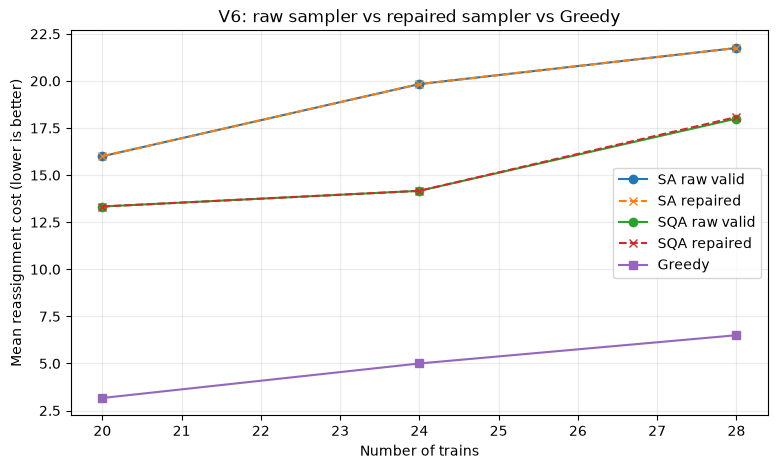

,algorithm,configuration,runs,mean_best_raw_cost,mean_raw_feasibility_pct,mean_best_repaired_cost,mean_repair_success_pct,median_runtime_s,errors
0,SA,beta_high,6,19.250000,66.666667,19.25,66.666667,0.147535,0
1,SA,beta_wide,6,19.666667,50.000000,19.00,66.666667,0.173693,0
2,SA,default,6,19.500000,66.666667,19.50,66.666667,0.144127,0
3,SQA,default,6,14.666667,50.000000,16.75,66.666667,1.826094,0
4,SQA,forward_linear_s_beta1,6,18.750000,66.666667,18.75,66.666667,1.724078,0
5,SQA,reverse_from_greedy,6,4.250000,66.666667,4.25,66.666667,1.594258,0


In [13]:
if not sampler_runs.empty:
    dataset_algorithm_summary = (sampler_runs.groupby(["dataset_id","n_trains","delay_max_min","algorithm"],dropna=False)
        .agg(repeats=("repeat","nunique"),mean_best_raw_cost=("best_raw_valid_cost","mean"),
             best_raw_cost_across_repeats=("best_raw_valid_cost","min"),mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             mean_best_repaired_cost=("best_repaired_cost","mean"),mean_repair_success_pct=("repair_success_pct","mean"),
             mean_runtime_s=("runtime_s","mean"),exact_hit_runs=("hit_exact_optimum",lambda s:int(s.dropna().astype(bool).sum())))
        .reset_index().merge(dataset_diagnostics[["dataset_id","exact_status","exact_proven_optimum_cost","greedy_cost"]],on="dataset_id",how="left"))
    dataset_algorithm_summary["gap_to_proven_optimum"] = np.where(
        dataset_algorithm_summary.exact_status=="OPTIMAL",
        dataset_algorithm_summary.mean_best_raw_cost-dataset_algorithm_summary.exact_proven_optimum_cost,np.nan)
    scaling_summary = (dataset_algorithm_summary.groupby(["n_trains","algorithm"],dropna=False)
        .agg(unique_datasets=("dataset_id","nunique"),mean_best_raw_cost=("mean_best_raw_cost","mean"),
             mean_raw_feasibility_pct=("mean_raw_feasibility_pct","mean"),
             mean_best_repaired_cost=("mean_best_repaired_cost","mean"),
             median_runtime_s=("mean_runtime_s","median"),exact_hit_runs=("exact_hit_runs","sum"),
             mean_gap_to_proven_optimum=("gap_to_proven_optimum","mean"))
        .reset_index())
else:
    dataset_algorithm_summary=scaling_summary=pd.DataFrame()

exact_summary = pd.DataFrame()
if not dataset_diagnostics.empty:
    exact_summary = dataset_diagnostics.groupby(["n_trains","exact_status"]).size().rename("datasets").reset_index()
    print("Exact status by train count:"); display(exact_summary)
if not scaling_summary.empty:
    print("Sampler summary by size:"); display(scaling_summary)
    fig,ax=plt.subplots(figsize=(9,5))
    for alg in ["SA","SQA"]:
        d=scaling_summary[scaling_summary.algorithm==alg]
        ax.plot(d.n_trains,d.mean_best_raw_cost,marker="o",label=f"{alg} raw valid")
        ax.plot(d.n_trains,d.mean_best_repaired_cost,marker="x",linestyle="--",label=f"{alg} repaired")
    greedy_curve=dataset_diagnostics.groupby("n_trains").greedy_cost.mean()
    ax.plot(greedy_curve.index,greedy_curve.values,marker="s",label="Greedy")
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Mean reassignment cost (lower is better)")
    ax.set_title("V6: raw sampler vs repaired sampler vs Greedy"); ax.grid(alpha=.25); ax.legend(); plt.show()

if not calibration_results.empty:
    calibration_summary=(calibration_results.groupby(["algorithm","configuration"])
        .agg(runs=("repeat","count"),mean_best_raw_cost=("best_raw_valid_cost","mean"),
             mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             mean_best_repaired_cost=("best_repaired_cost","mean"),
             mean_repair_success_pct=("repair_success_pct","mean"),median_runtime_s=("runtime_s","median"),
             errors=("run_status",lambda s:int((s!="OK").sum())))
        .reset_index())
    display(calibration_summary)
else:
    calibration_summary=pd.DataFrame()

## 13. Export all V6 records
Keep the executed notebook and every exported file together. The raw sampler-run file preserves every repeat; diagnostics and calibration results remain separate.

In [14]:
OUTPUT_DIR = Path.cwd() / "jaipur_v6_outputs"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

def export_frame(frame,name):
    if frame is None or frame.empty:
        print("Not exported (empty):",name); return
    path=OUTPUT_DIR/name
    frame.to_csv(path,index=False)
    print("Saved:",path)

export_frame(dataset_diagnostics,"jaipur_v6_dataset_diagnostics.csv")
export_frame(sampler_runs,"jaipur_v6_sampler_runs.csv")
export_frame(generated_train_tables,"jaipur_v6_generated_train_tables.csv")
export_frame(conflict_edge_tables,"jaipur_v6_conflict_edges.csv")
export_frame(qubo_checks,"jaipur_v6_qubo_checks.csv")
export_frame(energy_summary,"jaipur_v6_energy_landscape_summary.csv")
export_frame(feasible_move_table,"jaipur_v6_feasible_moves.csv")
export_frame(energy_path_table,"jaipur_v6_energy_paths.csv")
export_frame(calibration_results,"jaipur_v6_calibration_runs.csv")
export_frame(calibration_summary,"jaipur_v6_calibration_summary.csv")
export_frame(dataset_algorithm_summary,"jaipur_v6_dataset_algorithm_summary.csv")
export_frame(scaling_summary,"jaipur_v6_scaling_summary.csv")
export_frame(exact_summary,"jaipur_v6_exact_status_summary.csv")

metadata={
    "notebook_version":"v6","python_version":sys.version.split()[0],"platform":platform.platform(),
    "cpu":platform.processor(),"ram_gb":RAM_GB,"openjij_version":OPENJIJ_VERSION,
    "n_platforms":N_PLATFORMS,"clearance_min_assumption":BASE_CLEARANCE_MIN,
    "long_platform_count_main":LONG_PLATFORM_COUNT_MAIN,"long_train_coach_threshold":LONG_TRAIN_COACH_THRESHOLD,
    "train_counts":TRAIN_COUNTS_V6,"delay_levels_min":DELAY_LEVELS_V6,"dataset_seeds":DATASET_SEEDS,
    "dataset_count":len(dataset_diagnostics),"baseline_repeats":BASELINE_REPEATS,
    "num_reads":NUM_READS,"num_sweeps":NUM_SWEEPS,"exact_time_limit_by_n":EXACT_TIME_LIMIT_BY_N,
    "calibration_ids":CALIBRATION_IDS,"calibration_repeats":CALIBRATION_REPEATS,
    "qubo_all_dataset_checks_passed":bool(qubo_checks.passed.all()) if not qubo_checks.empty else None,
    "synthetic_data_notice":"Train-level schedules, delays, nominal platform assignments and coach counts are synthetic.",
    "quantum_notice":"OpenJij SQA is a classical simulation, not quantum hardware."
}
with open(OUTPUT_DIR/"jaipur_v6_experiment_metadata.json","w",encoding="utf-8") as f:
    json.dump(metadata,f,indent=2)
print("V6 export directory:",OUTPUT_DIR.resolve())

Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_dataset_diagnostics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_sampler_runs.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_generated_train_tables.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_conflict_edges.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_qubo_checks.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_energy_landscape_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_feasible_moves.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_energy_paths.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_calibration_runs.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\jaipur_v6_outputs\jaipur_v6_calibration_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\j

## 14. V6 interpretation checklist
Before using these results in a report or paper:

- Compare the V6 dataset IDs and synthetic train tables with V5; they should match for the 18 common IDs.
- Treat `OPTIMAL` as a proof, `TIMEOUT` as unknown, and `INFEASIBLE` as a completed infeasibility proof only.
- Report Exact Search's Greedy incumbent separately from a proven optimum.
- Keep raw sampler feasibility separate from repair-decoder success.
- Compare raw best costs with Greedy and with Exact only where Exact proved optimality.
- The energy-path diagnostic shows one specific two-flip route between assignments; it is not a full transition-state or spectral-gap analysis.
- Do not claim SQA is faster, better overall, or quantum-advantaged unless repeated, paired results support that conclusion.

### OpenJij parameter references
- OpenJij documentation: https://tutorial.openjij.org/en/
- Reverse annealing / initial-state and schedule example: https://tutorial.openjij.org/en/tutorial/optimization/ReverseQuantumAnnealing.html
- The SQA schedule entries used here follow the documented `[s, beta, Monte Carlo steps]` form. Check the output/error log if your installed OpenJij version rejects an optional custom schedule.